# Notebook 02 — Data Cleaning & Feature Engineering

**Input:** `data/raw/2016_Building_Energy_Benchmarking.csv`  
**Output:** `data/processed/data_modelisation.xlsx` — clean, model-ready dataset  
**Leads to:** `03_baseline_models.ipynb`

This notebook transforms the raw 3,376-row dataset into a clean **1,596-row dataset**
with **19 features** ready for machine learning. Every decision is documented with
the reasoning behind it.

---

**Contents**
1. Column selection — drop irrelevant variables
2. Data quality fixes — imputation, outlier removal, type standardisation
3. Visual inspection of the cleaned data
4. Feature engineering — create new predictors
5. Feature selection — remove redundant and correlated columns
6. Export


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)


In [2]:
import pandas as pd

# Load the dataset
data = pd.read_csv(r'../data/raw/2016_Building_Energy_Benchmarking.csv')

# Explore the data
print(data.head())
print(data.info())

   OSEBuildingID  DataYear    BuildingType PrimaryPropertyType  \
0              1      2016  NonResidential               Hotel   
1              2      2016  NonResidential               Hotel   
2              3      2016  NonResidential               Hotel   
3              5      2016  NonResidential               Hotel   
4              8      2016  NonResidential               Hotel   

                  PropertyName          Address     City State  ZipCode  \
0         Mayflower park hotel    405 Olive way  Seattle    WA  98101.0   
1              Paramount Hotel  724 Pine street  Seattle    WA  98101.0   
2      5673-The Westin Seattle  1900 5th Avenue  Seattle    WA  98101.0   
3                    HOTEL MAX   620 STEWART ST  Seattle    WA  98101.0   
4  WARWICK SEATTLE HOTEL (ID8)    401 LENORA ST  Seattle    WA  98121.0   

  TaxParcelIdentificationNumber  ...  Electricity(kWh) Electricity(kBtu)  \
0                    0659000030  ...      1.156514e+06         3946027.0   


## 1. Column Selection — Removing Irrelevant Variables

The raw dataset contains 60+ columns, many of which are not useful for prediction:

- **Administrative identifiers** (building ID, address, parcel number) — unique per row,
  no predictive value
- **Derived energy intensity metrics** (EUI per sqft) — computed from the target variables;
  using them would leak the answer into the features
- **Redundant unit conversions** — energy reported in both kWh and kBtu; we keep kBtu
  for consistency
- **Near-empty columns** (e.g., `Comments`, `YearsENERGYSTARCertified`) — insufficient
  fill rate to be useful

We also remove building types that appear only once — they cannot be represented reliably
in a train/test split.


In [3]:
# Define columns to drop
columns_to_drop = [
    'OSEBuildingID', 'DataYear', 'PropertyName', 'Address', 'City', 
    'State', 'TaxParcelIdentificationNumber', 'CouncilDistrictCode',
    'Neighborhood', 'Latitude', 'Longitude', 'PropertyGFATotal',
    'ListOfAllPropertyUseTypes', 'YearsENERGYSTARCertified',
    'SiteEUI(kBtu/sf)', 'SiteEUIWN(kBtu/sf)', 'SourceEUI(kBtu/sf)',
    'SourceEUIWN(kBtu/sf)', 'Electricity(kWh)', 'NaturalGas(therms)',
    'DefaultData', 'Comments', 'ComplianceStatus', 'GHGEmissionsIntensity','PrimaryPropertyType'
]  # Removed the extra single quote at the end

# Drop specified columns
data = data.drop(columns=columns_to_drop, errors='ignore')

import pandas as pd

# Step 1: Analyze and filter the 'building type' field
building_type_column = 'BuildingType'  # replace with actual column name for building type
before_count = data.shape[0]

building_type_counts = data[building_type_column].value_counts()
single_occurrences = building_type_counts[building_type_counts == 1].index
data = data[~data[building_type_column].isin(single_occurrences)]
after_count = data.shape[0]

print(f"Lines before removing single occurrence building types: {before_count}")
print(f"Lines after removing single occurrence building types: {after_count}")

Lines before removing single occurrence building types: 3376
Lines after removing single occurrence building types: 3375


## 2. Data Quality Fixes

### 2.1 Energy Column Imputation

The dataset contains two closely related energy columns:
- `SiteEnergyUse(kBtu)` — raw reported energy
- `SiteEnergyUseWN(kBtu)` — **weather-normalised** energy (our preferred target)

When the weather-normalised value is missing or zero, we fall back to the raw value.
Rows where both are zero or NaN are removed — they represent buildings with no
measurable energy footprint, which are outside our prediction scope.

The ratio histogram below confirms that the two columns are closely aligned (ratio ≈ 1)
for most buildings, validating the imputation.


Initial row count: 3375
Rows impacted by imputation: 5


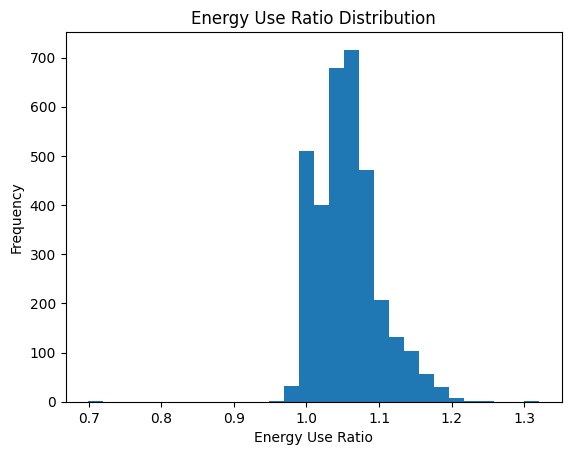

Rows impacted by filtering: 23
Final row count after dropping columns: 3352


In [4]:
import pandas as pd
import matplotlib.pyplot as plt


# Step 1: Initial count of rows
initial_count = data.shape[0]
print(f"Initial row count: {initial_count}")

# Step 2: Impute missing/zero values
data['SiteEnergyUseWN(kBtu)'].replace(0, pd.NA, inplace=True)
data['SiteEnergyUseWN(kBtu)'].fillna(data['SiteEnergyUse(kBtu)'], inplace=True)

# Count rows affected by imputation
imputation_count = data['SiteEnergyUseWN(kBtu)'].isna().sum()
print(f"Rows impacted by imputation: {imputation_count}")

# Step 3: Calculate ratio and visualize
data['EnergyUseRatio'] = data['SiteEnergyUseWN(kBtu)'] / data['SiteEnergyUse(kBtu)']

# Plot histogram of the Energy Use Ratio
plt.hist(data['EnergyUseRatio'].dropna(), bins=30)
plt.title('Energy Use Ratio Distribution')
plt.xlabel('Energy Use Ratio')
plt.ylabel('Frequency')
plt.show()

# Step 4: Filter out rows with 0 or NaN in SiteEnergyUseWN(kBtu)
filtered_data = data[data['SiteEnergyUseWN(kBtu)'].notna() & (data['SiteEnergyUseWN(kBtu)'] != 0)]
filtered_count = data.shape[0] - filtered_data.shape[0]
print(f"Rows impacted by filtering: {filtered_count}")

# Step 5: Drop unnecessary columns
data = filtered_data.drop(columns=['SiteEnergyUse(kBtu)', 'EnergyUseRatio'])
final_count = data.shape[0]
print(f"Final row count after dropping columns: {final_count}")


### 2.2 Flag-Based Outlier Removal

The original dataset includes an `Outlier` column produced by the city's own quality
control process, flagging buildings as `'High outlier'` or `'Low outlier'`. We remove
these rows rather than correct them — the city's domain experts have already determined
they are unreliable measurements.


In [5]:
import pandas as pd



# Step 1: Check initial data size
initial_count = data.shape[0]
print(f"Initial row count: {initial_count}")

# Step 2: Remove outlier observations
outlier_count = data[data['Outlier'].isin(['High outlier', 'Low outlier'])].shape[0]
data = data[~data['Outlier'].isin(['High outlier', 'Low outlier'])]

print(f"Rows removed: {outlier_count}")
print(f"Rows remaining: {data.shape[0]}")

# Step 3: Drop the Outlier column
# Remove outliers and drop column in one operation
data = data[~data['Outlier'].isin(['High outlier', 'Low outlier'])].drop(columns=['Outlier'])


print(f"Final dataset shape: {data.shape}")


Initial row count: 3352
Rows removed: 32
Rows remaining: 3320
Final dataset shape: (3320, 19)


In [6]:
data.head()


,BuildingType,ZipCode,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFAParking,PropertyGFABuilding(s),LargestPropertyUseType,LargestPropertyUseTypeGFA,SecondLargestPropertyUseType,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseType,ThirdLargestPropertyUseTypeGFA,ENERGYSTARScore,SiteEnergyUseWN(kBtu),SteamUse(kBtu),Electricity(kBtu),NaturalGas(kBtu),TotalGHGEmissions
0,NonResidential,98101.0,1927,1.0,12,0,88434,Hotel,88434.0,NaN,NaN,NaN,NaN,60.0,7456910.0,2003882.00,3946027.0,1276453.0,249.98
1,NonResidential,98101.0,1996,1.0,11,15064,88502,Hotel,83880.0,Parking,15064.0,Restaurant,4622.0,61.0,8664479.0,0.00,3242851.0,5145082.0,295.86
2,NonResidential,98101.0,1969,1.0,41,196718,759392,Hotel,756493.0,NaN,NaN,NaN,NaN,43.0,73937112.0,21566554.00,49526664.0,1493800.0,2089.28
3,NonResidential,98101.0,1926,1.0,10,0,61320,Hotel,61320.0,NaN,NaN,NaN,NaN,56.0,6946800.5,2214446.25,2768924.0,1811213.0,286.43
4,NonResidential,98121.0,1980,1.0,18,62000,113580,Hotel,123445.0,Parking,68009.0,Swimming Pool,0.0,75.0,14656503.0,0.00,5368607.0,8803998.0,505.01


### 2.3 Scope — Non-Residential Buildings Only

The project brief focuses on **non-residential commercial and institutional buildings**.
Multifamily residential buildings follow different energy patterns (driven by occupant
behaviour rather than building use type) and would dilute the model.

We remove all rows where `BuildingType` contains `'Multifamily'`.


In [7]:
import pandas as pd

# Count original dimensions
original_row_count = data.shape[0]
original_col_count = data.shape[1]

# Apply data cleaning (example: removing specific entries)
data = data[~data['BuildingType'].str.contains('Multifamily', case=False, na=False)]

# Count new dimensions
new_row_count = data.shape[0]
new_col_count = data.shape[1]

# Calculate impact
impacted_rows = original_row_count - new_row_count
impacted_columns = original_col_count - new_col_count

# Display systematic tracking results
print(f"Original rows: {original_row_count}")
print(f"New rows: {new_row_count}")
print(f"Impacted rows: {impacted_rows}")
print(f"Total columns: {original_col_count}")




Original rows: 3320


New rows: 1632
Impacted rows: 1688
Total columns: 19


In [8]:
data.head()


,BuildingType,ZipCode,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFAParking,PropertyGFABuilding(s),LargestPropertyUseType,LargestPropertyUseTypeGFA,SecondLargestPropertyUseType,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseType,ThirdLargestPropertyUseTypeGFA,ENERGYSTARScore,SiteEnergyUseWN(kBtu),SteamUse(kBtu),Electricity(kBtu),NaturalGas(kBtu),TotalGHGEmissions
0,NonResidential,98101.0,1927,1.0,12,0,88434,Hotel,88434.0,NaN,NaN,NaN,NaN,60.0,7456910.0,2003882.00,3946027.0,1276453.0,249.98
1,NonResidential,98101.0,1996,1.0,11,15064,88502,Hotel,83880.0,Parking,15064.0,Restaurant,4622.0,61.0,8664479.0,0.00,3242851.0,5145082.0,295.86
2,NonResidential,98101.0,1969,1.0,41,196718,759392,Hotel,756493.0,NaN,NaN,NaN,NaN,43.0,73937112.0,21566554.00,49526664.0,1493800.0,2089.28
3,NonResidential,98101.0,1926,1.0,10,0,61320,Hotel,61320.0,NaN,NaN,NaN,NaN,56.0,6946800.5,2214446.25,2768924.0,1811213.0,286.43
4,NonResidential,98121.0,1980,1.0,18,62000,113580,Hotel,123445.0,Parking,68009.0,Swimming Pool,0.0,75.0,14656503.0,0.00,5368607.0,8803998.0,505.01


### 2.4 Data Type Standardisation

Many numeric columns were loaded as `float64` due to NaN values. We cast them to
appropriate types:
- Categorical columns (BuildingType, use types) → `category`
- Integer-valued columns (floor counts, GFA) → `Int64` (nullable integer)
- ZipCode → `object` (it is an identifier, not a magnitude)

Correct types reduce memory usage and prevent silent numeric operations on
categorical fields.


In [9]:
# ==== Step X: convert variables to their proposed data types ====

type_map = {
    "BuildingType": "category",
    "ZipCode": "object",
    "NumberofBuildings": "int64",
    "LargestPropertyUseTypeGFA": "int64",
    "SecondLargestPropertyUseTypeGFA": "int64",
    "ThirdLargestPropertyUseTypeGFA": "int64",
    "ENERGYSTARScore": "int64",
    "SiteEnergyUseWN(kBtu)": "int64",
    "SteamUse(kBtu)": "int64",
    "Electricity(kBtu)": "int64",
    "NaturalGas(kBtu)": "int64",
    "TotalGHGEmissions": "int64"
}

# Apply conversions safely
for col, dtype in type_map.items():
    if col not in data.columns:
        print(f"⚠️ Skipping '{col}' — not found in dataframe.")
        continue
    try:
        if dtype == "category":
            data[col] = data[col].astype("category")
        elif dtype == "int64":
            # Handle non-integer values and missing data safely
            data[col] = pd.to_numeric(data[col], errors="coerce").astype("Int64")
        else:
            data[col] = data[col].astype(dtype)
        print(f"✅ Converted {col} → {dtype}")
    except Exception as e:
        print(f"❌ Could not convert {col} → {dtype} ({e})")

# Confirm
data.dtypes.loc[list(type_map.keys())]


✅ Converted BuildingType → category
✅ Converted ZipCode → object
✅ Converted NumberofBuildings → int64
✅ Converted LargestPropertyUseTypeGFA → int64
❌ Could not convert SecondLargestPropertyUseTypeGFA → int64 (cannot safely cast non-equivalent float64 to int64)
❌ Could not convert ThirdLargestPropertyUseTypeGFA → int64 (cannot safely cast non-equivalent float64 to int64)
✅ Converted ENERGYSTARScore → int64
❌ Could not convert SiteEnergyUseWN(kBtu) → int64 (cannot safely cast non-equivalent float64 to int64)
❌ Could not convert SteamUse(kBtu) → int64 (cannot safely cast non-equivalent float64 to int64)
❌ Could not convert Electricity(kBtu) → int64 (cannot safely cast non-equivalent float64 to int64)
❌ Could not convert NaturalGas(kBtu) → int64 (cannot safely cast non-equivalent float64 to int64)
❌ Could not convert TotalGHGEmissions → int64 (cannot safely cast non-equivalent object to int64)


BuildingType                       category
ZipCode                              object
NumberofBuildings                     Int64
LargestPropertyUseTypeGFA             Int64
SecondLargestPropertyUseTypeGFA     float64
ThirdLargestPropertyUseTypeGFA      float64
ENERGYSTARScore                       Int64
SiteEnergyUseWN(kBtu)               float64
SteamUse(kBtu)                      float64
Electricity(kBtu)                   float64
NaturalGas(kBtu)                    float64
TotalGHGEmissions                   float64
dtype: object

### 2.5 Use Type / GFA Consistency Validation

Each property can report up to three use types (largest, second, third) each with
a corresponding Gross Floor Area (GFA). An inconsistency occurs when a use type name
is provided but the GFA is zero or missing (or vice versa).

We clear the use type label in such cases — a use type without a floor area
is not meaningful for our models.


### 2.6 Missing Value Summary

After the above fixes we inspect what missingness remains before deciding
on imputation strategies for each column.


In [10]:
import pandas as pd
import numpy as np

UNAVAILABLE = {"", "na", "n/a", "none", "null", "nan", "not available", "not_available", "0", "0.0", "unknown"}

def is_unavailable_type(s: pd.Series) -> pd.Series:
    s2 = s.astype(str).str.strip().str.lower()
    return s.isna() | s2.isin(UNAVAILABLE)

def is_positive_gfa(s: pd.Series) -> pd.Series:
    s_num = pd.to_numeric(s, errors="coerce")
    return s_num > 0

pairs = [
    ("LargestPropertyUseType", "LargestPropertyUseTypeGFA"),
    ("SecondLargestPropertyUseType", "SecondLargestPropertyUseTypeGFA"),
    ("ThirdLargestPropertyUseType", "ThirdLargestPropertyUseTypeGFA"),
]

for col_type, col_gfa in pairs:
    if col_type not in data.columns or col_gfa not in data.columns:
        print(f"⚠️ Skipping: {col_type} or {col_gfa} not found")
        continue

    type_unavail = is_unavailable_type(data[col_type])
    type_has_value = ~type_unavail
    gfa_pos = is_positive_gfa(data[col_gfa])

    # --- Fix rule ---
    # If Type has value but GFA is not positive → make Type empty
    mask_fix = type_has_value & ~gfa_pos
    n_fix = mask_fix.sum()
    data.loc[mask_fix, col_type] = np.nan  # clear value

    print(f"✅ {col_type}: cleared {n_fix} inconsistent entries (Type had value but GFA≤0/NaN)")


✅ LargestPropertyUseType: cleared 0 inconsistent entries (Type had value but GFA≤0/NaN)
✅ SecondLargestPropertyUseType: cleared 77 inconsistent entries (Type had value but GFA≤0/NaN)
✅ ThirdLargestPropertyUseType: cleared 24 inconsistent entries (Type had value but GFA≤0/NaN)


### 2.7 Remove Rows with Missing or Zero Targets

Our two prediction targets are `SiteEnergyUseWN(kBtu)` and `TotalGHGEmissions`.
Rows where either target is zero or NaN cannot be used for supervised learning
and are removed.


In [11]:
import pandas as pd
import numpy as np

summary = pd.DataFrame({
    "NaN_Count": data.isna().sum(),
    "NaN_%": (data.isna().mean() * 100).round(2)
})

# Add zero stats for numeric columns only
numeric_cols = data.select_dtypes(include=[np.number]).columns
summary["Zero_Count"] = 0
summary.loc[numeric_cols, "Zero_Count"] = (data[numeric_cols] == 0).sum().values
summary["Zero_%"] = 0.0
summary.loc[numeric_cols, "Zero_%"] = ((data[numeric_cols] == 0).mean() * 100).round(2).values

# Sort by highest missingness
summary = summary.sort_values(["NaN_%", "Zero_%"], ascending=[False, False])

display(summary)

,NaN_Count,NaN_%,Zero_Count,Zero_%
ThirdLargestPropertyUseType,1305,79.96,0,0.00
ThirdLargestPropertyUseTypeGFA,1281,78.49,24,1.47
SecondLargestPropertyUseType,862,52.82,0,0.00
SecondLargestPropertyUseTypeGFA,785,48.10,77,4.72
ENERGYSTARScore,550,33.70,0,0.00
ZipCode,16,0.98,0,0.00
LargestPropertyUseType,4,0.25,0,0.00
LargestPropertyUseTypeGFA,4,0.25,0,0.00
SteamUse(kBtu),0,0.00,1518,93.01
PropertyGFAParking,0,0.00,1301,79.72


In [12]:
import pandas as pd
import numpy as np

# Define the target variables to check
targets = ["TotalGHGEmissions", "SiteEnergyUseWN(kBtu)"]

before = len(data)

# Keep only rows where BOTH targets > 0 and not NaN
mask_valid = (data[targets] > 0).all(axis=1)
mask_valid &= data[targets].notna().all(axis=1)

data = data.loc[mask_valid].copy()
after = len(data)

print(f"✅ Removed {before - after} rows where any target variable was 0 or NaN")
print(f"Remaining rows: {after}")


✅ Removed 2 rows where any target variable was 0 or NaN
Remaining rows: 1630


### 2.8 Fill Remaining Missing Values

- **GFA columns** (second/third use type GFA): missing means the building has no
  second or third use — fill with `0`.
- **ZipCode**: a small number of buildings have no zip code recorded — fill with
  `'unknown'` so the column remains usable as a categorical feature.


In [13]:
gfa_cols = [
    "LargestPropertyUseTypeGFA",
    "SecondLargestPropertyUseTypeGFA",
    "ThirdLargestPropertyUseTypeGFA"
]

for col in gfa_cols:
    if col in data.columns:
        n_missing = data[col].isna().sum()
        data[col] = data[col].fillna(0)
        print(f"✅ Replaced {n_missing} NaN values with 0 in '{col}'")
    else:
        print(f"⚠️ Column '{col}' not found — skipped.")


✅ Replaced 4 NaN values with 0 in 'LargestPropertyUseTypeGFA'
✅ Replaced 784 NaN values with 0 in 'SecondLargestPropertyUseTypeGFA'
✅ Replaced 1280 NaN values with 0 in 'ThirdLargestPropertyUseTypeGFA'


In [14]:
if "ZipCode" in data.columns:
    n_missing = data["ZipCode"].isna().sum()
    data["ZipCode"] = data["ZipCode"].fillna("unknown")
    print(f"✅ Replaced {n_missing} NaN values in 'ZipCode' with 'unknown'")
else:
    print("⚠️ 'ZipCode' column not found in data")



✅ Replaced 16 NaN values in 'ZipCode' with 'unknown'


### 2.9 Dataset Snapshot After Cleaning

A quick summary of the dataset shape and remaining missingness after all cleaning steps.


In [15]:
data.describe()

,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFAParking,PropertyGFABuilding(s),LargestPropertyUseTypeGFA,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseTypeGFA,ENERGYSTARScore,SiteEnergyUseWN(kBtu),SteamUse(kBtu),Electricity(kBtu),NaturalGas(kBtu),TotalGHGEmissions
count,1630.000000,1630.0,1630.000000,1630.000000,1.630000e+03,1630.0,1630.000000,1630.000000,1080.0,1.630000e+03,1.630000e+03,1.630000e+03,1.630000e+03,1630.000000
mean,1962.005521,1.169939,4.160123,13156.692638,1.061585e+05,98757.65092,18808.755397,3210.178159,65.158333,8.789222e+06,5.238932e+05,5.920308e+06,2.004537e+06,188.172043
std,32.692861,2.961999,6.630066,42713.437154,2.855767e+05,278291.037237,51210.451444,18166.161800,28.357246,3.090225e+07,5.574006e+06,2.098730e+07,9.469382e+06,759.820319
min,1900.000000,0.0,0.000000,0.000000,3.636000e+03,0.0,0.000000,0.000000,1.0,5.811420e+04,0.000000e+00,0.000000e+00,0.000000e+00,0.400000
25%,1930.000000,1.0,1.000000,0.000000,2.837525e+04,25500.0,0.000000,0.000000,48.0,1.366622e+06,0.000000e+00,7.437612e+05,0.000000e+00,20.940000
50%,1966.000000,1.0,2.000000,0.000000,4.716000e+04,43525.5,0.000000,0.000000,73.0,2.787996e+06,0.000000e+00,1.642952e+06,5.256470e+05,50.610000
75%,1989.000000,1.0,4.000000,0.000000,9.530650e+04,92004.5,12863.000000,0.000000,89.0,7.338307e+06,0.000000e+00,4.971464e+06,1.530282e+06,145.030000
max,2015.000000,111.0,99.000000,512608.000000,9.320156e+06,9320156.0,639931.000000,459748.000000,100.0,8.739237e+08,1.349435e+08,6.570744e+08,2.979090e+08,16870.980000


### 2.10 Dataset Summary After Cleaning

Descriptive statistics confirm the scale and spread of all features and that no unexpected missingness remains before feature engineering.


## 3. Visual Inspection of the Cleaned Data

With the dataset cleaned, we visualise the most informative relationships
to confirm that distributions are sensible and key patterns are preserved
before engineering features.

The four plots below show energy use against the most predictive structural
attributes: building type, ENERGY STAR certification, use category, and age.
Log scale is applied to the y-axis to handle the right-skewed distribution.


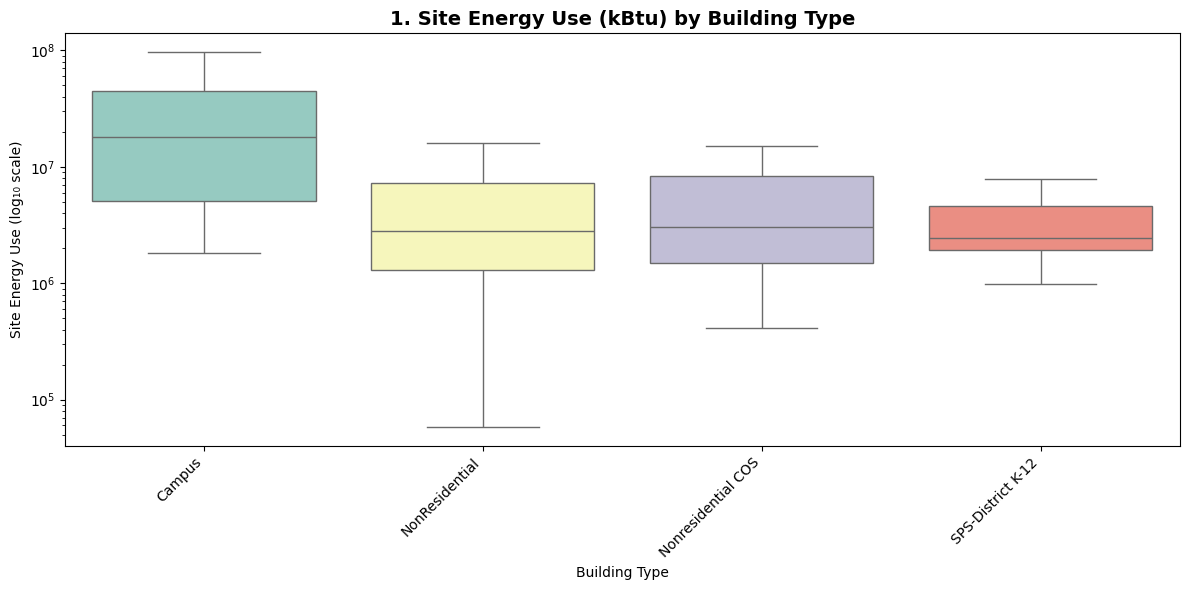

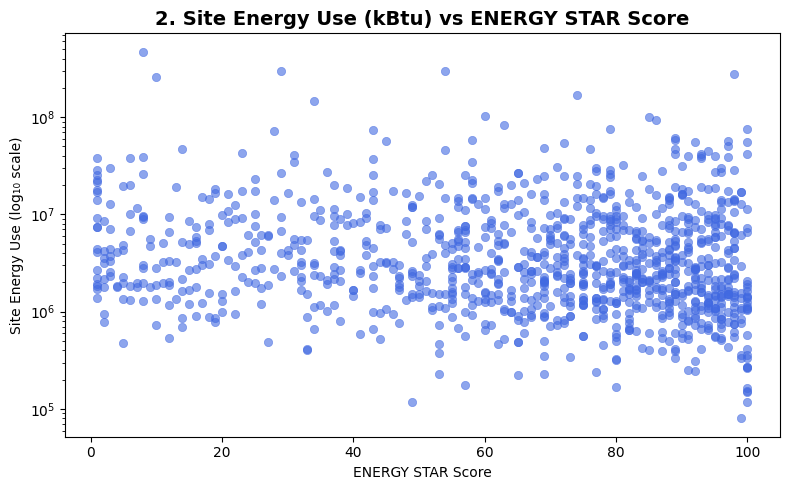

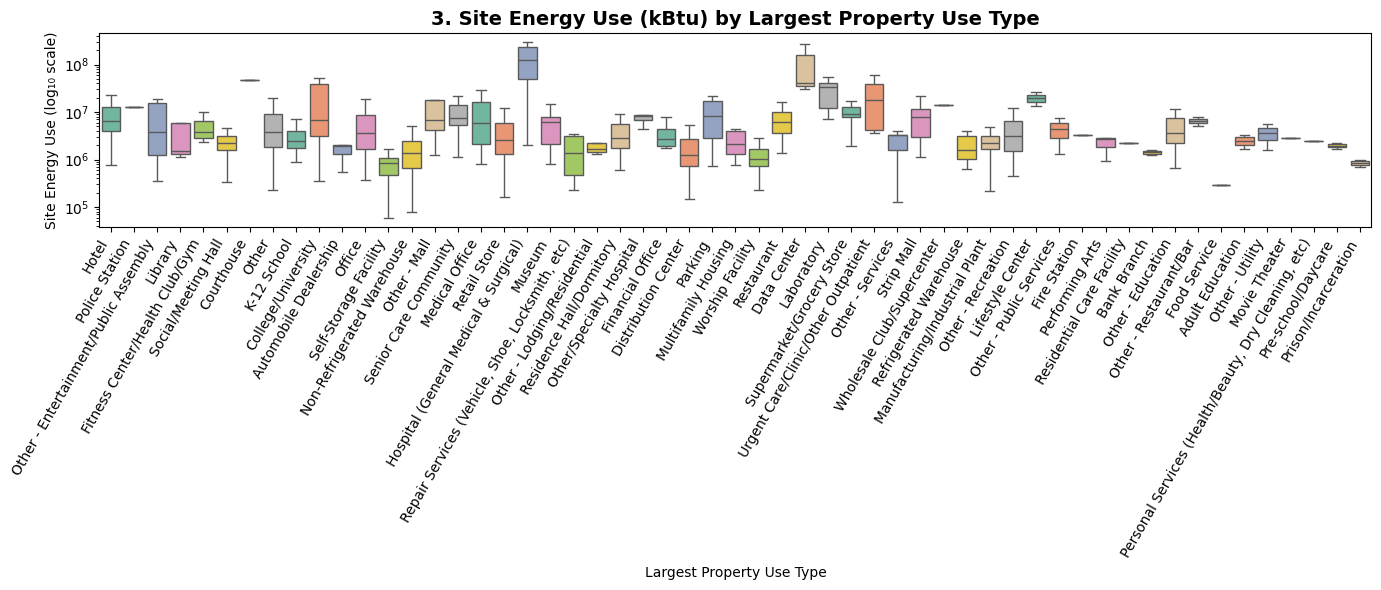

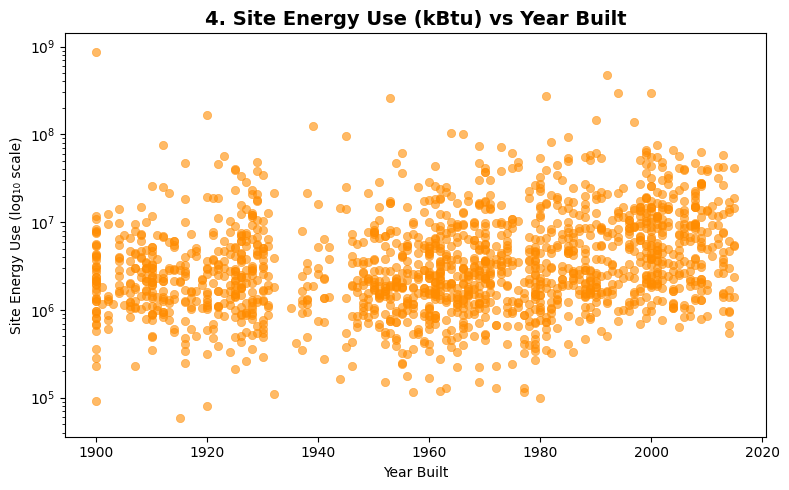

In [16]:
import seaborn as sns
import matplotlib.pyplot as plt

# --- 1️⃣ BuildingType vs SiteEnergyUseWN(kBtu) ---
plt.figure(figsize=(12, 6))
sns.boxplot(
    data=data,
    x="BuildingType",
    y="SiteEnergyUseWN(kBtu)",
    palette="Set3",
    showfliers=False
)
plt.yscale("log")
plt.title("1. Site Energy Use (kBtu) by Building Type", fontsize=14, fontweight="bold")
plt.xlabel("Building Type")
plt.ylabel("Site Energy Use (log₁₀ scale)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


# --- 2️⃣ SiteEnergyUseWN(kBtu) vs ENERGYSTARScore ---
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=data,
    x="ENERGYSTARScore",
    y="SiteEnergyUseWN(kBtu)",
    alpha=0.6,
    color="royalblue",
    edgecolor=None
)
plt.yscale("log")
plt.title("2. Site Energy Use (kBtu) vs ENERGY STAR Score", fontsize=14, fontweight="bold")
plt.xlabel("ENERGY STAR Score")
plt.ylabel("Site Energy Use (log₁₀ scale)")
plt.tight_layout()
plt.show()


# --- 3️⃣ LargestPropertyUseType vs SiteEnergyUseWN(kBtu) ---
plt.figure(figsize=(14, 6))
sns.boxplot(
    data=data,
    x="LargestPropertyUseType",
    y="SiteEnergyUseWN(kBtu)",
    palette="Set2",
    showfliers=False
)
plt.yscale("log")
plt.title("3. Site Energy Use (kBtu) by Largest Property Use Type", fontsize=14, fontweight="bold")
plt.xlabel("Largest Property Use Type")
plt.ylabel("Site Energy Use (log₁₀ scale)")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.show()


# --- 4️⃣ YearBuilt vs SiteEnergyUseWN(kBtu) ---
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=data,
    x="YearBuilt",
    y="SiteEnergyUseWN(kBtu)",
    alpha=0.6,
    color="darkorange",
    edgecolor=None
)
plt.yscale("log")
plt.title("4. Site Energy Use (kBtu) vs Year Built", fontsize=14, fontweight="bold")
plt.xlabel("Year Built")
plt.ylabel("Site Energy Use (log₁₀ scale)")
plt.tight_layout()
plt.show()


## 4. Feature Engineering — Creating New Predictors

The raw columns describe physical attributes of buildings. We engineer additional
features that capture relationships the models cannot easily learn from raw values alone.

Each feature is motivated by domain knowledge about what drives building energy use.


### 4.1 Building Age

Older buildings were constructed before modern energy codes and are more likely
to have inefficient envelopes and HVAC systems. `Age = current year − YearBuilt`
converts an absolute year into a relative measure of expected energy performance.


In [17]:
import pandas as pd
from datetime import datetime

current_year = datetime.now().year  # dynamically gets the current year
data["Age"] = current_year - data["YearBuilt"]

# Replace any negative or invalid ages (from future YearBuilt) with NaN
data.loc[data["Age"] < 0, "Age"] = pd.NA

print(f"✅ Created new feature 'Age' (Current year = {current_year})")
display(data[["YearBuilt", "Age"]].head())


✅ Created new feature 'Age' (Current year = 2026)


,YearBuilt,Age
0,1927,99.0
1,1996,30.0
2,1969,57.0
3,1926,100.0
4,1980,46.0


### 4.2 ENERGY STAR Score — Binary Flag and Imputation

`ENERGYSTARScore` is a 1–100 certification score for energy efficiency. It is
missing for ~35% of buildings. We handle it in two steps:

1. **Binary flag** `hasEnergyStarScore` — records whether a building has a score at all.
   This is itself informative: certified buildings tend to be newer or better managed.
2. **Imputation** — fill missing scores with the mean score for that `BuildingType`,
   preserving the column for use as a numeric feature while avoiding data leakage
   from the full-dataset mean.

> Note: Notebook `04_energy_star_analysis.ipynb` explores the predictive power of
> this score in depth.


In [18]:
import numpy as np
import pandas as pd

# Create binary flag: 1 if score > 0, else 0 (also handles NaN)
data["hasEnergyStarScore"] = np.where(data["ENERGYSTARScore"].fillna(0) > 0, 1, 0)

print("✅ Created new feature: 'hasEnergyStarScore'")
display(data[["ENERGYSTARScore", "hasEnergyStarScore"]].head(10))

# Quick summary
print("\nDistribution of hasEnergyStarScore:")
print(data["hasEnergyStarScore"].value_counts())


✅ Created new feature: 'hasEnergyStarScore'


,ENERGYSTARScore,hasEnergyStarScore
0,60,1
1,61,1
2,43,1
3,56,1
4,75,1
5,<NA>,0
6,27,1
7,<NA>,0
8,43,1
10,30,1



Distribution of hasEnergyStarScore:
hasEnergyStarScore
1    1080
0     550
Name: count, dtype: int64


In [19]:
import pandas as pd
import numpy as np

# 1️⃣ Clean invalid or text entries
data["ENERGYSTARScore"] = pd.to_numeric(data["ENERGYSTARScore"], errors="coerce")

# 2️⃣ Treat 0 and NaN as missing
data.loc[data["ENERGYSTARScore"] == 0, "ENERGYSTARScore"] = np.nan

# 3️⃣ Compute mean ENERGY STAR score by BuildingType
mean_by_type = data.groupby("BuildingType")["ENERGYSTARScore"].mean()

# 4️⃣ Fill missing values with the BuildingType mean
data["ENERGYSTARScore"] = data.apply(
    lambda row: mean_by_type[row["BuildingType"]]
    if pd.isna(row["ENERGYSTARScore"]) and row["BuildingType"] in mean_by_type
    else row["ENERGYSTARScore"],
    axis=1
)

print("✅ Filled missing or zero ENERGY STAR scores using BuildingType mean.")
display(data[["BuildingType", "ENERGYSTARScore"]].head(15))

✅ Filled missing or zero ENERGY STAR scores using BuildingType mean.

,BuildingType,ENERGYSTARScore
0,NonResidential,60.000000
1,NonResidential,61.000000
2,NonResidential,43.000000
3,NonResidential,56.000000
4,NonResidential,75.000000
5,Nonresidential COS,60.909091
6,NonResidential,27.000000
7,NonResidential,63.593082
8,NonResidential,43.000000
10,NonResidential,30.000000


### 4.3 Largest Use Type Floor Area Share

`Ratio_LargestPropertyShare = LargestPropertyUseTypeGFA / PropertyGFABuilding(s)`

This ratio captures how **single-purpose** a building is. A ratio close to 1 means
the building is almost entirely devoted to one use; a lower ratio indicates a more
mixed-use building. Mixed-use buildings tend to have more complex energy profiles.

Ratios > 1 (data entry errors) are set to NaN.


In [20]:
import numpy as np
import pandas as pd

# Avoid division by zero or NaN in the denominator
denominator = data["PropertyGFABuilding(s)"].replace(0, np.nan)

# Compute ratio safely
data["Ratio_LargestPropertyShare"] = data["LargestPropertyUseTypeGFA"] / denominator

# Cap unrealistic ratios > 1.0 (e.g., due to data entry errors)
data.loc[data["Ratio_LargestPropertyShare"] > 1, "Ratio_LargestPropertyShare"] = np.nan

print("✅ Created new feature: 'Ratio_LargestPropertyShare'")
display(data[["LargestPropertyUseTypeGFA", "PropertyGFABuilding(s)", "Ratio_LargestPropertyShare"]].head(10))


✅ Created new feature: 'Ratio_LargestPropertyShare'


,LargestPropertyUseTypeGFA,PropertyGFABuilding(s),Ratio_LargestPropertyShare
0,88434,88434,1.0
1,83880,88502,0.947775
2,756493,759392,0.996182
3,61320,61320,1.0
4,123445,113580,<NA>
5,88830,60090,<NA>
6,81352,83008,0.98005
7,102761,102761,1.0
8,163984,163984,1.0
10,133884,133884,1.0


### 4.4 Energy Source Ratios

Total site energy is composed of electricity, natural gas, and steam. The **share**
of each source is more informative than the absolute amounts, because it captures
the building's energy profile independently of its size.

- `Ratio_ElectricityShare = Electricity(kBtu) / SiteEnergyUseWN(kBtu)`
- `Ratio_NaturalGasShare = NaturalGas(kBtu) / SiteEnergyUseWN(kBtu)`

Ratios > 1 are capped at NaN (physically impossible, likely reporting errors).


In [21]:
import numpy as np
import pandas as pd

# Avoid division by zero or NaN in denominator
denominator = data["SiteEnergyUseWN(kBtu)"].replace(0, np.nan)

# Compute ratios safely
data["Ratio_ElectricityShare"] = data["Electricity(kBtu)"] / denominator
data["Ratio_NaturalGasShare"] = data["NaturalGas(kBtu)"] / denominator

# Cap invalid ratios > 1.0 (since a share >100% is not physically possible)
for col in ["Ratio_ElectricityShare", "Ratio_NaturalGasShare"]:
    data.loc[data[col] > 1, col] = np.nan

print("✅ Created new features: 'Ratio_ElectricityShare' and 'Ratio_NaturalGasShare'")
display(data[["Electricity(kBtu)", "NaturalGas(kBtu)", "SiteEnergyUseWN(kBtu)",
              "Ratio_ElectricityShare", "Ratio_NaturalGasShare"]].head(10))


✅ Created new features: 'Ratio_ElectricityShare' and 'Ratio_NaturalGasShare'


,Electricity(kBtu),NaturalGas(kBtu),SiteEnergyUseWN(kBtu),Ratio_ElectricityShare,Ratio_NaturalGasShare
0,3946027.0,1276453.0,7456910.0,0.529177,0.171177
1,3242851.0,5145082.0,8664479.0,0.374270,0.593813
2,49526664.0,1493800.0,73937112.0,0.669849,0.020204
3,2768924.0,1811213.0,6946800.5,0.398590,0.260726
4,5368607.0,8803998.0,14656503.0,0.366295,0.600689
5,7371434.0,4715182.0,12581712.0,0.585885,0.374765
6,2811215.0,2947580.0,6062767.5,0.463685,0.486177
7,3636655.0,385189.0,7067881.5,0.514533,0.054499
8,7297919.0,6425900.0,14194054.0,0.514153,0.452718
10,6187627.0,4591850.0,16646930.0,0.371698,0.275838


### 4.5 Energy Mix Category

`EnergyMix` encodes **which combination of energy sources** a building uses:
- `E` = electricity only
- `EN` = electricity + natural gas
- `SEN` = steam + electricity + natural gas
- etc.

This categorical feature captures the structural energy infrastructure of the building
(e.g., whether it is connected to the district steam network), which is a meaningful
predictor of total consumption.


In [22]:
import pandas as pd
import numpy as np

# Temporary flags for each energy source
data["S_flag"] = np.where(data["SteamUse(kBtu)"] > 0, "S", "")
data["E_flag"] = np.where(data["Electricity(kBtu)"] > 0, "E", "")
data["N_flag"] = np.where(data["NaturalGas(kBtu)"] > 0, "N", "")

# Concatenate flags to form Energy Mix labels
data["EnergyMix"] = (data["S_flag"] + data["E_flag"] + data["N_flag"]).replace("", np.nan)

# Drop the temporary helper columns
data.drop(columns=["S_flag", "E_flag", "N_flag"], inplace=True)

# Convert to category type for modeling efficiency
data["EnergyMix"] = data["EnergyMix"].astype("category")

# Display summary
print("✅ Created new feature: 'EnergyMix'")
display(data[["SteamUse(kBtu)", "Electricity(kBtu)", "NaturalGas(kBtu)", "EnergyMix"]].head(10))

# Quick frequency check
print("\nEnergy Mix distribution:")
print(data["EnergyMix"].value_counts(dropna=False))


✅ Created new feature: 'EnergyMix'


,SteamUse(kBtu),Electricity(kBtu),NaturalGas(kBtu),EnergyMix
0,2003882.00,3946027.0,1276453.0,SEN
1,0.00,3242851.0,5145082.0,EN
2,21566554.00,49526664.0,1493800.0,SEN
3,2214446.25,2768924.0,1811213.0,SEN
4,0.00,5368607.0,8803998.0,EN
5,0.00,7371434.0,4715182.0,EN
6,0.00,2811215.0,2947580.0,EN
7,2276286.50,3636655.0,385189.0,SEN
8,0.00,7297919.0,6425900.0,EN
10,5237165.50,6187627.0,4591850.0,SEN



Energy Mix distribution:
EnergyMix
EN     1114
E       401
SEN      63
SE       51
N         1
Name: count, dtype: int64


### 4.6 Mixed-Use Building Flag

`isMixedProperty = 1` if the building has **more than one non-parking use type**.
Mixed-use buildings tend to have more diverse energy demand patterns and often
consume more energy than single-use buildings of the same size.


In [23]:
import pandas as pd
import numpy as np

# Helper: columns to check
use_cols = [
    "LargestPropertyUseType",
    "SecondLargestPropertyUseType",
    "ThirdLargestPropertyUseType"
]

# Normalize text: lowercase and strip spaces for consistency
for col in use_cols:
    if col in data.columns:
        data[col] = data[col].astype(str).str.strip().str.lower()

# Define a function to count distinct non-parking uses
def count_non_parking(row):
    types = [t for t in row if pd.notna(t) and t not in ["parking", "nan", "none", ""]]
    return len(set(types))

# Apply the function row-wise
data["isMixedProperty"] = data[use_cols].apply(count_non_parking, axis=1).gt(1).astype(int)

print("✅ Created new feature: 'isMixedProperty' (1 = mixed-use, 0 = single-use)")
display(data[use_cols + ["isMixedProperty"]].head(10))

# Optional: check distribution
print("\nDistribution of isMixedProperty:")
print(data["isMixedProperty"].value_counts())


✅ Created new feature: 'isMixedProperty' (1 = mixed-use, 0 = single-use)


,LargestPropertyUseType,SecondLargestPropertyUseType,ThirdLargestPropertyUseType,isMixedProperty
0,hotel,nan,nan,0
1,hotel,parking,restaurant,1
2,hotel,nan,nan,0
3,hotel,nan,nan,0
4,hotel,parking,nan,0
5,police station,nan,nan,0
6,hotel,nan,nan,0
7,other - entertainment/public assembly,nan,nan,0
8,hotel,nan,nan,0
10,hotel,nan,nan,0



Distribution of isMixedProperty:
isMixedProperty
0    1034
1     596
Name: count, dtype: int64


## 5. Feature Selection — Removing Redundancy

After engineering, we have more features than we need. We remove columns that:
- Were **decomposed into ratios** (raw energy source columns → ratio features)
- Are **highly correlated** with other features (correlation > 0.7)

Reducing redundancy improves model training speed and reduces the risk of overfitting.


In [24]:
# Display all column names
print("✅ Columns in data:")
for col in data.columns:
    print(col)


✅ Columns in data:
BuildingType
ZipCode
YearBuilt
NumberofBuildings
NumberofFloors
PropertyGFAParking
PropertyGFABuilding(s)
LargestPropertyUseType
LargestPropertyUseTypeGFA
SecondLargestPropertyUseType
SecondLargestPropertyUseTypeGFA
ThirdLargestPropertyUseType
ThirdLargestPropertyUseTypeGFA
ENERGYSTARScore
SiteEnergyUseWN(kBtu)
SteamUse(kBtu)
Electricity(kBtu)
NaturalGas(kBtu)
TotalGHGEmissions
Age
hasEnergyStarScore
Ratio_LargestPropertyShare
Ratio_ElectricityShare
Ratio_NaturalGasShare
EnergyMix
isMixedProperty


In [25]:
cols_to_drop = [
    "YearBuilt",
    "SteamUse(kBtu)",
    "Electricity(kBtu)",
    "NaturalGas(kBtu)"
]

data = data.drop(columns=[c for c in cols_to_drop if c in data.columns])
print(f"✅ Dropped {len(cols_to_drop)} columns (only those present).")
print("Remaining columns:", len(data.columns))


✅ Dropped 4 columns (only those present).
Remaining columns: 22


In [26]:
import pandas as pd
import numpy as np

def null_zero_summary(df):
    summary = pd.DataFrame({
        "DataType": df.dtypes.astype(str),  # convert dtype safely to string
        "NaN_Count": df.isna().sum(),
        "NaN_%": round(df.isna().mean() * 100, 2),
    })

    zero_counts = {}
    zero_perc = {}

    for col in df.columns:
        # Use pandas dtype checker instead of np.issubdtype
        if pd.api.types.is_numeric_dtype(df[col]):
            zeros = (df[col] == 0).sum()
            zero_counts[col] = zeros
            zero_perc[col] = round((zeros / len(df)) * 100, 2)
        else:
            zero_counts[col] = "-"
            zero_perc[col] = "-"

    summary["Zero_Count"] = summary.index.map(zero_counts)
    summary["Zero_%"] = summary.index.map(zero_perc)

    return summary.sort_values(by=["NaN_Count", "Zero_Count"], ascending=False)

# Run summary
summary_df = null_zero_summary(data)
print("✅ NaN and Zero Summary per Column:")
display(summary_df)


✅ NaN and Zero Summary per Column:

,DataType,NaN_Count,NaN_%,Zero_Count,Zero_%
Ratio_LargestPropertyShare,Float64,338,20.74,4,0.25
Ratio_ElectricityShare,float64,58,3.56,1,0.06
BuildingType,category,0,0.00,-,-
ZipCode,object,0,0.00,-,-
LargestPropertyUseType,object,0,0.00,-,-
SecondLargestPropertyUseType,object,0,0.00,-,-
ThirdLargestPropertyUseType,object,0,0.00,-,-
EnergyMix,category,0,0.00,-,-
ThirdLargestPropertyUseTypeGFA,float64,0,0.00,1304,80.0
PropertyGFAParking,int64,0,0.00,1299,79.69


### 5.1 Correlation Analysis

The heatmap below shows Pearson correlations between all numeric features.
Pairs with |r| > 0.7 are candidates for removal — keeping both adds noise
without adding information.


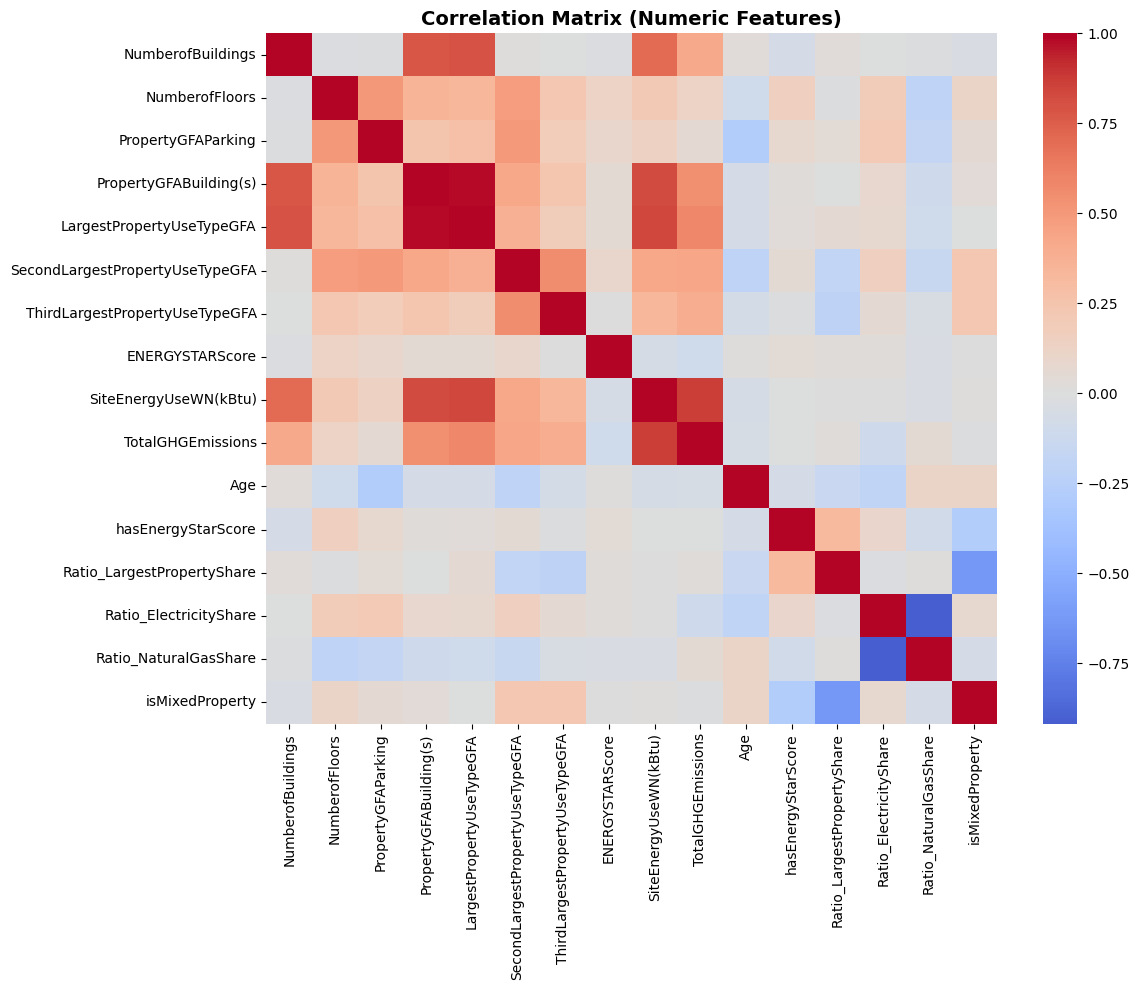

✅ Strong correlations (|r| > 0.7):


,Feature_1,Feature_2,Correlation
0,PropertyGFABuilding(s),LargestPropertyUseTypeGFA,0.982333
1,Ratio_ElectricityShare,Ratio_NaturalGasShare,0.917839
2,SiteEnergyUseWN(kBtu),TotalGHGEmissions,0.866875
3,LargestPropertyUseTypeGFA,SiteEnergyUseWN(kBtu),0.842073
4,PropertyGFABuilding(s),SiteEnergyUseWN(kBtu),0.821511
5,NumberofBuildings,LargestPropertyUseTypeGFA,0.799991
6,NumberofBuildings,PropertyGFABuilding(s),0.775676
7,NumberofBuildings,SiteEnergyUseWN(kBtu),0.707175


In [27]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# ---- Step 1: Compute correlation matrix (numeric only)
numeric_df = data.select_dtypes(include=[np.number])
corr_matrix = numeric_df.corr(method="pearson")

# ---- Step 2: Plot correlation heatmap
plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, cmap="coolwarm", center=0, annot=False)
plt.title("Correlation Matrix (Numeric Features)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

# ---- Step 3: Extract pairs with |correlation| > 0.7
# Use stack() to unpivot the matrix and filter
corr_pairs = (
    corr_matrix.abs()
    .where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))  # upper triangle only
    .stack()
    .reset_index()
    .rename(columns={"level_0": "Feature_1", "level_1": "Feature_2", 0: "Correlation"})
)

# Filter strong correlations
high_corr = corr_pairs[corr_pairs["Correlation"] > 0.7].sort_values(
    by="Correlation", ascending=False
).reset_index(drop=True)

print("✅ Strong correlations (|r| > 0.7):")
display(high_corr)




### 5.2 Drop Correlated Features

From the correlation analysis, we remove:
- `Ratio_NaturalGasShare` — strongly correlated with `Ratio_ElectricityShare`
  (the two shares sum to ≈ 1 for most buildings)
- `PropertyGFABuilding(s)` — near-collinear with `LargestPropertyUseTypeGFA`
- `NumberofBuildings` — low variance, low signal


In [28]:
cols_to_drop = [
    "Ratio_NaturalGasShare",
    "PropertyGFABuilding(s)",
    "NumberofBuildings"
   
]

data = data.drop(columns=[c for c in cols_to_drop if c in data.columns])
print(f"✅ Dropped {len(cols_to_drop)} columns (only those present).")
print("Remaining columns:", len(data.columns))

✅ Dropped 3 columns (only those present).
Remaining columns: 19


### 5.3 Final Outlier Removal on Target Variables

Even after the flag-based removal, a small number of extreme values remain in
the target columns. We cap both targets at the **99th percentile** to prevent
a handful of very large buildings from dominating the loss function during training.

This step removes ~34 rows (2% of the cleaned dataset), a negligible loss.


In [29]:
data.head()

,BuildingType,ZipCode,NumberofFloors,PropertyGFAParking,LargestPropertyUseType,LargestPropertyUseTypeGFA,SecondLargestPropertyUseType,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseType,ThirdLargestPropertyUseTypeGFA,ENERGYSTARScore,SiteEnergyUseWN(kBtu),TotalGHGEmissions,Age,hasEnergyStarScore,Ratio_LargestPropertyShare,Ratio_ElectricityShare,EnergyMix,isMixedProperty
0,NonResidential,98101.0,12,0,hotel,88434,nan,0.0,nan,0.0,60.0,7456910.0,249.98,99.0,1,1.0,0.529177,SEN,0
1,NonResidential,98101.0,11,15064,hotel,83880,parking,15064.0,restaurant,4622.0,61.0,8664479.0,295.86,30.0,1,0.947775,0.374270,EN,1
2,NonResidential,98101.0,41,196718,hotel,756493,nan,0.0,nan,0.0,43.0,73937112.0,2089.28,57.0,1,0.996182,0.669849,SEN,0
3,NonResidential,98101.0,10,0,hotel,61320,nan,0.0,nan,0.0,56.0,6946800.5,286.43,100.0,1,1.0,0.398590,SEN,0
4,NonResidential,98121.0,18,62000,hotel,123445,parking,68009.0,nan,0.0,75.0,14656503.0,505.01,46.0,1,<NA>,0.366295,EN,0


## 6. Export — Final Dataset Ready for Modelling

The cleaned dataset is exported to `data/processed/data_modelisation.xlsx`.
This file is the **single source of truth** for all modelling notebooks:
- `03_baseline_models.ipynb`
- `04_energy_star_analysis.ipynb`
- `05_final_model_and_results.ipynb`

**Final dataset shape:** 1,596 rows × 19 columns  
**Targets:** `SiteEnergyUseWN(kBtu)`, `TotalGHGEmissions`


In [30]:
import pandas as pd
import numpy as np

# Copy to preserve original
data_clean = data.copy()

# Variables to clean
target_cols = ["TotalGHGEmissions", "SiteEnergyUseWN(kBtu)"]

# Initialize summary table
removed_summary = []

initial_rows = len(data_clean)

for col in target_cols:
    if col in data_clean.columns:
        p99 = data_clean[col].quantile(0.99)
        before = len(data_clean)
        data_clean = data_clean[data_clean[col] <= p99]
        after = len(data_clean)
        removed = before - after
        removed_summary.append({
            "Column": col,
            "99th Percentile": round(p99, 2),
            "Rows_Removed": removed,
            "Rows_Remaining": after
        })

# Convert to summary dataframe
removed_df = pd.DataFrame(removed_summary)

print("✅ Outlier removal summary (99th percentile):")
display(removed_df)

print(f"Total rows before filtering: {initial_rows}")
print(f"Total rows after filtering: {len(data_clean)}")
print(f"Total rows deleted overall: {initial_rows - len(data_clean)}")
data = data_clean

✅ Outlier removal summary (99th percentile):


,Column,99th Percentile,Rows_Removed,Rows_Remaining
0,TotalGHGEmissions,2036.88,17,1613
1,SiteEnergyUseWN(kBtu),54960673.76,17,1596


Total rows before filtering: 1630
Total rows after filtering: 1596
Total rows deleted overall: 34


## Summary of Decisions

| Step | Before | After | Reason |
|---|---|---|---|
| Column selection | 60+ columns | ~19 features | Drop identifiers, derived metrics, redundant units |
| Multifamily removal | 3,376 rows | 1,632 rows | Out of project scope |
| Outlier / quality removal | 1,632 | 1,596 rows | Flag-based + 99th percentile |
| Engineered features | 0 new | 6 new | Age, EnergyMix, ratios, flags |
| Correlation pruning | 22 columns | 19 columns | Remove near-duplicate features |

**Next:** `03_baseline_models.ipynb` — establish a performance baseline using
all 19 features with 7 different model families.
